# A national fire history from the open archives

Every fire NASA FIRMS saw in Italy with VIIRS S-NPP, year by year since 2012,
from the yearly country archives: no key, about 2 MB a year, downloaded once
into the data directory (`$DATA_ROOT/firms-client`, else
`~/.cache/firms-client`).

Three things to keep in mind while reading the chart:

- **A detection is a hot pixel, not a fire.** One fire is many detections:
  the chart counts **fire-days** (days with at least one vegetation fire in a
  1 km cell), which a large fire does not inflate as much.
- **Not every hot pixel is a fire.** Steelworks, gas flares and Etna are hot
  every year. `select()` keeps the vegetation fires using the FIRMS `type`.
- **No detection is not no fire.** Clouds, smoke and the overpass time hide
  fires: these are the fires FIRMS saw, not all the fires.

In [1]:
from collections import Counter
from datetime import date

import httpx
import matplotlib.pyplot as plt

from firms_client import ATTRIBUTION, VIIRS_SNPP, fetch_archive, select
from firms_client.sources import archive_years

COUNTRY = "Italy"
years = {}
async with httpx.AsyncClient(timeout=300) as client:
    for year in archive_years(VIIRS_SNPP, until=date.today().year - 1):
        rows = await fetch_archive(client, VIIRS_SNPP, year, COUNTRY)
        if rows is not None:  # None: not published yet
            years[year] = rows
print(f"{len(years)} years, {sum(map(len, years.values())):,} detections")

14 years, 342,236 detections


## Detections, fires and fire-days

The rows of an archive are detections of every kind. `select()` keeps the
vegetation fires (FIRMS `type` 0, confidence nominal or high); the rest are
volcanoes, industry and platforms at sea.

In [2]:
def cell(h, size=0.01):
    return (round(h.latitude / size), round(h.longitude / size))


def fire_days(fires):
    return len({(cell(h), h.acq_date) for h in fires})


table = []
for year, rows in sorted(years.items()):
    fires = select(rows)
    table.append((year, len(rows), len(fires), fire_days(fires)))
print(f"{'year':>4} {'detections':>11} {'fires':>8} {'fire-days':>10} {'not fire':>9}")
for year, n, f, d in table:
    print(f"{year:>4} {n:>11,} {f:>8,} {d:>10,} {1 - f / n:>9.0%}")

year  detections    fires  fire-days  not fire
2012      35,824   22,987     16,484       36%
2013      21,888   11,534      9,152       47%
2014      23,894   12,871     10,071       46%
2015      21,034   12,175      9,478       42%
2016      22,390   13,605     10,507       39%
2017      38,569   26,617     18,076       31%
2018      16,291    8,432      6,734       48%
2019      23,530   13,893     10,765       41%
2020      21,951   13,674     10,514       38%
2021      31,831   20,648     13,818       35%
2022      21,046   12,088      9,211       43%
2023      25,318   16,449     12,069       35%
2024      15,321    9,044      6,891       41%
2025      23,349   14,880     10,954       36%


## North, Centre, South and islands

The same fire-days by latitude: the North above 44° N, the Centre from
41.5° N, the South and the islands below. A rough split, enough to see that
the fires of Italy are mostly in the South and in the islands.

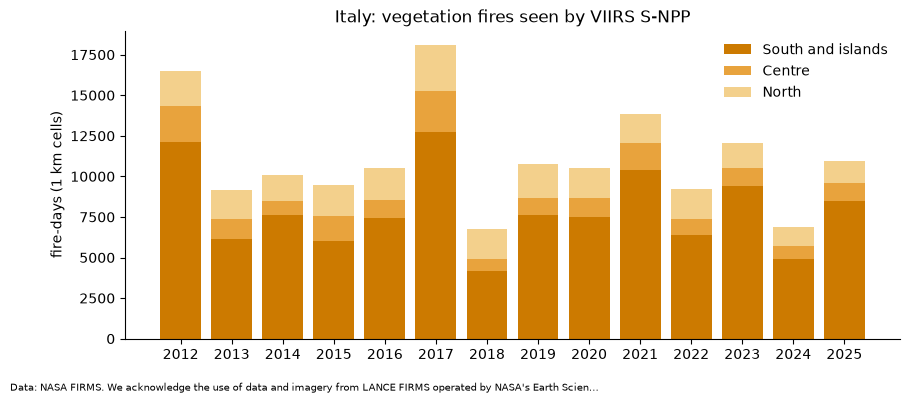

In [3]:
def band(h):
    return "North" if h.latitude >= 44 else "Centre" if h.latitude >= 41.5 else "South and islands"


bands = ["South and islands", "Centre", "North"]
per_band = {b: [] for b in bands}
for _year, rows in sorted(years.items()):
    by = Counter()
    for h in {(cell(h), h.acq_date): h for h in select(rows)}.values():
        by[band(h)] += 1
    for b in bands:
        per_band[b].append(by[b])

labels = [str(y) for y in sorted(years)]
fig, ax = plt.subplots(figsize=(10, 4))
bottom = [0] * len(labels)
for b, colour in zip(bands, ["#cc7a00", "#e8a33d", "#f3d08c"], strict=True):
    ax.bar(labels, per_band[b], bottom=bottom, label=b, color=colour)
    bottom = [x + y for x, y in zip(bottom, per_band[b], strict=True)]
ax.set_ylabel("fire-days (1 km cells)")
ax.set_title("Italy: vegetation fires seen by VIIRS S-NPP")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, -0.02, "Data: NASA FIRMS. " + ATTRIBUTION[:90] + "…", fontsize=7)
plt.show()

## How to cite

Anything published with these data carries the NASA acknowledgement:

In [4]:
print(ATTRIBUTION)

We acknowledge the use of data and imagery from LANCE FIRMS operated by NASA's Earth Science Data and Information System (ESDIS) with funding provided by NASA Headquarters.
